# Last-Mile Delivery Intelligence Platform

## Phase 1 — Data Understanding

### Objective

Build an end-to-end machine learning system for predicting last-mile
delivery time and identifying deliveries at risk of delay.

### Dataset

India Food Delivery Time Prediction

### Initial Business Problem

Given information available around the time an order is picked up,
predict the expected delivery duration.

### Prediction Target

`Time_taken(min)`

### Initial Prediction Point

Order pickup

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np

In [2]:
DATA_PATH = Path(
    "../data/raw/India-Food-Delivery-Time-Prediction.txt"
)

with open(DATA_PATH ,"r",encoding="utf-8") as f :
    data = json.load(f)

print(type(data))
print(len(data))

<class 'list'>
41953


In [3]:
print(data[0])

{'ID': '0x4607 ', 'Delivery_person_ID': 'INDORES13DEL02 ', 'Delivery_person_Age': '37', 'Delivery_person_Ratings': '4.9', 'Restaurant_latitude': 22.745049, 'Restaurant_longitude': 75.892471, 'Delivery_location_latitude': 22.765049, 'Delivery_location_longitude': 75.912471, 'Order_Date': '19-03-2022', 'Time_Orderd': '11:33:33', 'Time_Order_picked': '11:45:29', 'Weatherconditions': 'conditions Sunny', 'Road_traffic_density': 'High ', 'Vehicle_condition': 2, 'Type_of_order': 'Snack ', 'Type_of_vehicle': 'motorcycle ', 'multiple_deliveries': '0', 'Festival': 'No ', 'City': 'Urban ', 'Time_taken(min)': '(min) 24'}


In [4]:
print(data[0].keys())

dict_keys(['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'])


In [5]:
# Creating the DAtaframe

df = pd.DataFrame(data)

print(f"Rows : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Rows : 41,953
Columns : 20


In [6]:
# check first 5 top Columns
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:33:33,11:45:29,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:37,19:51:49,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,8:32:58,8:48:47,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:03:58,18:12:52,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:34:16,13:45:36,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [7]:
# Checking Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41953 entries, 0 to 41952
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           41953 non-null  str    
 1   Delivery_person_ID           41953 non-null  str    
 2   Delivery_person_Age          41953 non-null  str    
 3   Delivery_person_Ratings      41953 non-null  str    
 4   Restaurant_latitude          41953 non-null  float64
 5   Restaurant_longitude         41953 non-null  float64
 6   Delivery_location_latitude   41953 non-null  float64
 7   Delivery_location_longitude  41953 non-null  float64
 8   Order_Date                   41953 non-null  str    
 9   Time_Orderd                  40353 non-null  str    
 10  Time_Order_picked            41953 non-null  str    
 11  Weatherconditions            41953 non-null  str    
 12  Road_traffic_density         41953 non-null  str    
 13  Vehicle_condition          

In [8]:
df.dtypes  # this will help us to check the type of data in DF available

ID                                 str
Delivery_person_ID                 str
Delivery_person_Age                str
Delivery_person_Ratings            str
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                         str
Time_Orderd                        str
Time_Order_picked                  str
Weatherconditions                  str
Road_traffic_density               str
Vehicle_condition                int64
Type_of_order                      str
Type_of_vehicle                    str
multiple_deliveries                str
Festival                           str
City                               str
Time_taken(min)                    str
dtype: object

In [9]:
# Missing Values
missing_report = pd.DataFrame({
    "missing_count" : df.isna().sum(),
    "missing_percentage" : (df.isna().mean() * 100
                            ).round(2)
})
missing_report = (missing_report.sort_values("missing_percentage",ascending=False))

missing_report

,missing_count,missing_percentage
Time_Orderd,1600,3.81
ID,0,0.00
Delivery_person_Age,0,0.00
Delivery_person_ID,0,0.00
Delivery_person_Ratings,0,0.00
Restaurant_latitude,0,0.00
Delivery_location_latitude,0,0.00
Restaurant_longitude,0,0.00
Delivery_location_longitude,0,0.00
Order_Date,0,0.00


In [10]:
# Duplicate Records
print("Duplicate rows:",df.duplicated().sum())
print("Duplicate IDs :",df['ID'].duplicated().sum())

Duplicate rows: 0
Duplicate IDs : 0


In [11]:
# Inspect cateogrical variables

categorical_columns = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]
for col in categorical_columns :
    print(f"\n{'=' * 60}")
    print(f"{col}")
    print(df[col].value_counts(dropna=False))


Weatherconditions
Weatherconditions
conditions Fog           7012
conditions Stormy        6974
conditions Cloudy        6932
conditions Sandstorms    6906
conditions Windy         6832
conditions Sunny         6728
conditions NaN            569
Name: count, dtype: int64

Road_traffic_density
Road_traffic_density
Low        14200
Jam        13043
Medium     10084
High        4071
NaN          555
Name: count, dtype: int64

Type_of_order
Type_of_order
Snack      10616
Meal       10524
Drinks     10445
Buffet     10368
Name: count, dtype: int64

Type_of_vehicle
Type_of_vehicle
motorcycle           24396
scooter              14029
electric_scooter      3468
bicycle                 60
Name: count, dtype: int64

Festival
Festival
No      40916
Yes       822
NaN       215
Name: count, dtype: int64

City
City
Metropolitian     31411
Urban              9279
NaN                1114
Semi-Urban          149
Name: count, dtype: int64


In [12]:
# Inspect Numeric Candidates

numeric_candidates = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken(min)"
]
for col in numeric_candidates :
    print(f"\n{'=' * 60}")
    print(col)
    print(df[col].head(10).tolist())


Delivery_person_Age
['37', '34', '23', '38', '32', '22', '33', '35', '22', '36']

Delivery_person_Ratings
['4.9', '4.5', '4.4', '4.7', '4.6', '4.8', '4.7', '4.6', '4.8', '4.2']

Restaurant_latitude
[22.745049, 12.913041, 12.914264, 11.003669, 12.972793, 17.431668, 23.369746, 12.352058, 17.433809, 30.327968]

Restaurant_longitude
[75.892471, 77.683237, 77.6784, 76.976494, 80.249982, 78.408321, 85.33982, 76.60665, 78.386744, 78.046106]

Delivery_location_latitude
[22.765049, 13.043041, 12.924264, 11.053669, 13.012793, 17.461668, 23.479746, 12.482058, 17.563809, 30.397968]

Delivery_location_longitude
[75.912471, 77.813237, 77.6884, 77.026494, 80.289982, 78.438321, 85.44982, 76.73665, 78.516744, 78.116106]

Vehicle_condition
[2, 2, 0, 0, 1, 0, 1, 2, 0, 2]

multiple_deliveries
['0', '1', '1', '1', '1', '1', '1', '1', '1', '3']

Time_taken(min)
['(min) 24', '(min) 33', '(min) 26', '(min) 21', '(min) 30', '(min) 26', '(min) 40', '(min) 32', '(min) 34', '(min) 46']


In [13]:
# Inspecting the Target Value
print(df['Time_taken(min)'].value_counts().sort_index().head(20))

Time_taken(min)
(min) 10     693
(min) 11     699
(min) 12     682
(min) 13     663
(min) 14     677
(min) 15    1645
(min) 16    1579
(min) 17    1546
(min) 18    1604
(min) 19    1675
(min) 20    1510
(min) 21    1465
(min) 22    1499
(min) 23    1512
(min) 24    1537
(min) 25    1899
(min) 26    1960
(min) 27    1826
(min) 28    1794
(min) 29    1795
Name: count, dtype: int64


In [14]:
print("unique target values :",df["Time_taken(min)"].nunique())

unique target values : 45


In [15]:
df["Time_taken(min)"].tail(10)

41943    (min) 20
41944    (min) 29
41945    (min) 20
41946    (min) 42
41947    (min) 29
41948    (min) 33
41949    (min) 32
41950    (min) 16
41951    (min) 26
41952    (min) 36
Name: Time_taken(min), dtype: str

In [16]:
# Inspect the geographical Data
coordinate_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

df[coordinate_columns].describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
count,41953.000000,41953.000000,41953.000000,41953.000000
mean,18.911397,76.923408,18.975064,76.987074
std,5.467829,3.502910,5.469616,3.503073
min,9.957144,72.768726,9.967144,72.778726
25%,12.986047,73.898520,13.065996,73.940327
50%,19.065838,76.618203,19.123249,76.663622
75%,22.751234,78.368855,22.820040,78.405467
max,30.914057,88.433452,31.054057,88.563452


In [17]:
print("Order dates :")
print(df["Order_Date"].head(10))

print("\nOrder times :")
print(df["Time_Orderd"].head(10))

print("\nPickup Time : ")
print(df["Time_Order_picked"].head(10))



Order dates :
0    19-03-2022
1    25-03-2022
2    19-03-2022
3    05-04-2022
4    26-03-2022
5    11-03-2022
6    04-03-2022
7    14-03-2022
8    20-03-2022
9    12-02-2022
Name: Order_Date, dtype: str

Order times :
0    11:33:33
1    19:45:37
2     8:32:58
3    18:03:58
4    13:34:16
5    21:23:28
6    19:19:19
7    17:29:18
8    20:56:37
9    21:59:01
Name: Time_Orderd, dtype: str

Pickup Time : 
0    11:45:29
1    19:51:49
2     8:48:47
3    18:12:52
4    13:45:36
5    21:30:20
6    19:34:16
7    17:31:55
8    21:06:20
9    22:10:28
Name: Time_Order_picked, dtype: str


In [18]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='str')

In [19]:
print("Unique order Dates : ",df["Order_Date"].nunique())

Unique order Dates :  44


In [20]:
print(df["Order_Date"].value_counts().sort_index())

Order_Date
01-03-2022    1071
01-04-2022    1060
02-03-2022     944
02-04-2022     933
03-03-2022    1075
03-04-2022    1101
04-03-2022     922
04-04-2022     886
05-03-2022    1079
05-04-2022    1091
06-03-2022     921
06-04-2022     894
07-03-2022    1075
08-03-2022     908
09-03-2022    1088
10-03-2022     933
11-02-2022     799
11-03-2022    1079
12-02-2022     717
12-03-2022     910
13-02-2022     785
13-03-2022    1095
14-02-2022     707
14-03-2022     910
15-02-2022     785
15-03-2022    1115
16-02-2022     727
16-03-2022     928
17-02-2022     776
17-03-2022    1062
18-02-2022     720
18-03-2022     910
19-03-2022    1078
20-03-2022     933
21-03-2022    1079
23-03-2022     903
24-03-2022    1091
25-03-2022     918
26-03-2022    1093
27-03-2022     901
28-03-2022    1065
29-03-2022     914
30-03-2022    1068
31-03-2022     904
Name: count, dtype: int64


In [21]:
# Snapshot of the raw Data Structure
print("Dataset Shape :",df.shape)
print("\nColumns : ")
for i,col in enumerate(df.columns,start=1) :
    print(f"{i : 02d}.{col}")

Dataset Shape : (41953, 20)

Columns : 
 1.ID
 2.Delivery_person_ID
 3.Delivery_person_Age
 4.Delivery_person_Ratings
 5.Restaurant_latitude
 6.Restaurant_longitude
 7.Delivery_location_latitude
 8.Delivery_location_longitude
 9.Order_Date
 10.Time_Orderd
 11.Time_Order_picked
 12.Weatherconditions
 13.Road_traffic_density
 14.Vehicle_condition
 15.Type_of_order
 16.Type_of_vehicle
 17.multiple_deliveries
 18.Festival
 19.City
 20.Time_taken(min)


# 2. Data Quality Assessment

The objective of this section is to identify data-quality issues in the
raw dataset before applying any transformations.

The audit covers:

- Missing values
- Duplicate records
- Duplicate identifiers
- Invalid values
- Data type inconsistencies
- Whitespace inconsistencies
- Categorical cardinality
- Numerical ranges
- Geographic validity
- Temporal validity
- Target validity

In [22]:
print(f"Rows : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")
print(f"Memory : {df.memory_usage(deep = True).sum() / 1024**2:.2f}MB")

Rows : 41,953
Columns : 20
Memory : 35.56MB


In [23]:
dtype_report = pd.DataFrame({
    "column" : df.columns,
    "dtype" : df.dtypes.astype(str).values,
    "non_null" : df.notna().sum().values,
    "missing" : df.isna().sum().values


})

dtype_report

,column,dtype,non_null,missing
0,ID,str,41953,0
1,Delivery_person_ID,str,41953,0
2,Delivery_person_Age,str,41953,0
3,Delivery_person_Ratings,str,41953,0
4,Restaurant_latitude,float64,41953,0
5,Restaurant_longitude,float64,41953,0
6,Delivery_location_latitude,float64,41953,0
7,Delivery_location_longitude,float64,41953,0
8,Order_Date,str,41953,0
9,Time_Orderd,str,40353,1600


In [24]:
missing_report = (
    df.isna()
    .sum()
    .to_frame("missing_count")
)
missing_report["missing_percentage"] = (
    missing_report["missing_count"]/len(df) * 100
).round(2)
missing_report = missing_report.sort_values(
    "missing_percentage",
    ascending=False
)
missing_report

,missing_count,missing_percentage
Time_Orderd,1600,3.81
ID,0,0.00
Delivery_person_Age,0,0.00
Delivery_person_ID,0,0.00
Delivery_person_Ratings,0,0.00
Restaurant_latitude,0,0.00
Delivery_location_latitude,0,0.00
Restaurant_longitude,0,0.00
Delivery_location_longitude,0,0.00
Order_Date,0,0.00


In [25]:
missing_tokens = [
    "",
    " ",
    "NaN",
    "nan",
    "NA",
    "N/A",
    "null",
    "None"
]
for token in missing_tokens :
    count = (df == token).sum().sum()
    if count > 0 :
        print(f"{repr(token)} ->{count :,} occurences")

In [26]:
# Duplicate Audit
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["ID"].duplicated().sum()
duplicate_delivery_persons = df["Delivery_person_ID"].duplicated().sum()

print(f"Duplicate complete rows : {duplicate_rows:,}")
print(f"Duplicate order IDs : {duplicate_ids :,}")
print(f"Duplicate_delivery_persons : {duplicate_delivery_persons}")

Duplicate complete rows : 0
Duplicate order IDs : 0
Duplicate_delivery_persons : 40783


In [27]:
# Whitespace audit

string_columns = df.select_dtypes(include = 'object').columns
whitespace_report = {}
for col in string_columns :
    values = df[col].dropna().astype(str)
    whitespace_report[col] = (values.str.strip() != values).sum()

whitespace_report = (
    pd.Series(whitespace_report,name = 'values_with_outer_whitespace')
      .sort_values(ascending=False)
)
whitespace_report

C:\Users\A MAHESH\AppData\Local\Temp\ipykernel_21220\4214267094.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = df.select_dtypes(include = 'object').columns


ID                         41953
Delivery_person_ID         41953
City                       41953
Festival                   41953
Type_of_vehicle            41953
Type_of_order              41953
Road_traffic_density       41953
Delivery_person_Ratings     1763
Delivery_person_Age         1719
multiple_deliveries          905
Order_Date                     0
Time_Order_picked              0
Time_Orderd                    0
Weatherconditions              0
Time_taken(min)                0
Name: values_with_outer_whitespace, dtype: int64

In [28]:
# categorical Cardinality

categorical_columns = [
     "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]
cardinality_report = pd.DataFrame({
    "unique_values" : df[categorical_columns].nunique(dropna = False),
    "missing_values" : df[categorical_columns].isna().sum()
})
cardinality_report

,unique_values,missing_values
Weatherconditions,7,0
Road_traffic_density,5,0
Type_of_order,4,0
Type_of_vehicle,4,0
Festival,3,0
City,4,0


In [29]:
for col in categorical_columns :
    print(f"\n{col}")
    print(df[col].value_counts(dropna = False))


Weatherconditions
Weatherconditions
conditions Fog           7012
conditions Stormy        6974
conditions Cloudy        6932
conditions Sandstorms    6906
conditions Windy         6832
conditions Sunny         6728
conditions NaN            569
Name: count, dtype: int64

Road_traffic_density
Road_traffic_density
Low        14200
Jam        13043
Medium     10084
High        4071
NaN          555
Name: count, dtype: int64

Type_of_order
Type_of_order
Snack      10616
Meal       10524
Drinks     10445
Buffet     10368
Name: count, dtype: int64

Type_of_vehicle
Type_of_vehicle
motorcycle           24396
scooter              14029
electric_scooter      3468
bicycle                 60
Name: count, dtype: int64

Festival
Festival
No      40916
Yes       822
NaN       215
Name: count, dtype: int64

City
City
Metropolitian     31411
Urban              9279
NaN                1114
Semi-Urban          149
Name: count, dtype: int64


In [62]:
# Numerical Range Audit (We have several columns that should eventually be numerical.)

numeric_cadidates = [
   "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken(min)"
]
for col in numeric_candidates :
    print(f"\n{'=' * 70}")
    print(col)
    print("Unique:",df[col].nunique(dropna=False))
    print("sample :",df[col].dropna().unique()[:10])


Delivery_person_Age
Unique: 23
sample : <StringArray>
['37', '34', '23', '38', '32', '22', '33', '35', '36', '21']
Length: 10, dtype: str

Delivery_person_Ratings
Unique: 29
sample : <StringArray>
['4.9', '4.5', '4.4', '4.7', '4.6', '4.8', '4.2', '4.3', '4', '4.1']
Length: 10, dtype: str

Restaurant_latitude
Unique: 388
sample : [22.745049 12.913041 12.914264 11.003669 12.972793 17.431668 23.369746
 12.352058 17.433809 30.327968]

Restaurant_longitude
Unique: 388
sample : [75.892471 77.683237 77.6784   76.976494 80.249982 78.408321 85.33982
 76.60665  78.386744 78.046106]

Delivery_location_latitude
Unique: 4362
sample : [22.765049 13.043041 12.924264 11.053669 13.012793 17.461668 23.479746
 12.482058 17.563809 30.397968]

Delivery_location_longitude
Unique: 4362
sample : [75.912471 77.813237 77.6884   77.026494 80.289982 78.438321 85.44982
 76.73665  78.516744 78.116106]

Vehicle_condition
Unique: 4
sample : [2 0 1 3]

multiple_deliveries
Unique: 5
sample : <StringArray>
['0', '1', '

In [31]:
# Geographical Validity(checking distance Feature)

geo_columns =  ["Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
] 
df[geo_columns].describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
count,41953.000000,41953.000000,41953.000000,41953.000000
mean,18.911397,76.923408,18.975064,76.987074
std,5.467829,3.502910,5.469616,3.503073
min,9.957144,72.768726,9.967144,72.778726
25%,12.986047,73.898520,13.065996,73.940327
50%,19.065838,76.618203,19.123249,76.663622
75%,22.751234,78.368855,22.820040,78.405467
max,30.914057,88.433452,31.054057,88.563452


In [32]:
for col in  geo_columns :
    print(
        f"{col} :"
        f"min={df[col].min()},"
        f"max={df[col].max()}"
    )

Restaurant_latitude :min=9.957144,max=30.914057
Restaurant_longitude :min=72.768726,max=88.433452
Delivery_location_latitude :min=9.967144,max=31.054057
Delivery_location_longitude :min=72.778726,max=88.563452


In [33]:
# Date Audit

print(df['Order_Date'].describe())
print("\nUnique dates:",df["Order_Date"].nunique())
print("\nSample:")
print(df["Order_Date"].head(20).tolist())

count          41953
unique            44
top       15-03-2022
freq            1115
Name: Order_Date, dtype: object

Unique dates: 44

Sample:
['19-03-2022', '25-03-2022', '19-03-2022', '05-04-2022', '26-03-2022', '11-03-2022', '04-03-2022', '14-03-2022', '20-03-2022', '12-02-2022', '13-02-2022', '04-03-2022', '13-02-2022', '14-02-2022', '02-04-2022', '01-03-2022', '16-03-2022', '20-03-2022', '15-02-2022', '16-03-2022']


In [34]:
parsed_dates = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y",
    errors = "coerce"
)
print("Invalid_dates :",parsed_dates.isna().sum())
print("minimum_date :",parsed_dates.min())
print("maximum_date :",parsed_dates.max())

Invalid_dates : 0
minimum_date : 2022-02-11 00:00:00
maximum_date : 2022-04-06 00:00:00


In [35]:
for col in ["Time_Orderd","Time_Order_picked"] :
    parsed_time = pd.to_datetime(
        df[col],
        format = "%H:%M:%S",
        errors = "coerce"
    )
    print(f"\n{col}")
    print("Invalid :",parsed_time.isna().sum())
    print("Minimum : ",parsed_time.min())
    print("Maximum :",parsed_time.max())


Time_Orderd
Invalid : 1600
Minimum :  1900-01-01 00:00:00
Maximum : 1900-01-01 23:59:57

Time_Order_picked
Invalid : 0
Minimum :  1900-01-01 00:00:02
Maximum : 1900-01-01 23:59:57


In [36]:
# Target column Audit

target = df["Time_taken(min)"]

print("unique target values :",target.nunique())
print("\nMost common values :",)
print(target.value_counts().head(20))

unique target values : 45

Most common values :
Time_taken(min)
(min) 26    1960
(min) 25    1899
(min) 27    1826
(min) 29    1795
(min) 28    1794
(min) 19    1675
(min) 15    1645
(min) 18    1604
(min) 16    1579
(min) 17    1546
(min) 24    1537
(min) 23    1512
(min) 20    1510
(min) 22    1499
(min) 21    1465
(min) 33    1186
(min) 30    1134
(min) 31    1128
(min) 34    1081
(min) 32    1038
Name: count, dtype: int64


In [37]:
target_sample =  target.dropna().astype(str).head(20)
for value in target_sample :
    print(repr(value))

'(min) 24'
'(min) 33'
'(min) 26'
'(min) 21'
'(min) 30'
'(min) 26'
'(min) 40'
'(min) 32'
'(min) 34'
'(min) 46'
'(min) 23'
'(min) 21'
'(min) 20'
'(min) 41'
'(min) 20'
'(min) 33'
'(min) 40'
'(min) 41'
'(min) 15'
'(min) 36'


In [38]:
order_date = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

order_time = pd.to_timedelta(
    df["Time_Orderd"],
    errors="coerce"
)

pickup_time = pd.to_timedelta(
    df["Time_Order_picked"],
    errors="coerce"
)

In [39]:
order_timestamp = order_date + order_time
pickup_timestamp = order_date + pickup_time

In [40]:
pickup_wait_minutes = (
    pickup_timestamp - order_timestamp
).dt.total_seconds() / 60
pickup_wait_minutes.describe()

count    40353.000000
mean       -16.037530
std        189.788237
min      -1439.500000
25%          5.516667
50%          9.283333
75%         13.133333
max         19.883333
dtype: float64

**At the exact moment the prediction is made, what information would a real delivery system actually know?**

# 3. Data Dictionary

The purpose of this section is to understand the business meaning,
analytical role, and prediction-time availability of each raw feature.

Before preprocessing or feature engineering, each variable is classified
according to:

- Business meaning
- Raw data type
- Analytical type
- Feature/target role
- Availability at prediction time
- Potential leakage risk

In [41]:
data_dictionary = pd.DataFrame([
    {
        "column": "ID",
        "business_meaning": "Unique order identifier",
        "role": "Identifier",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Delivery_person_ID",
        "business_meaning": "Unique delivery person identifier",
        "role": "Driver Identifier",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Medium"
    },
    {
        "column": "Delivery_person_Age",
        "business_meaning": "Age of delivery person",
        "role": "Feature",
        "analytical_type": "Numeric",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Delivery_person_Ratings",
        "business_meaning": "Delivery person rating",
        "role": "Feature",
        "analytical_type": "Numeric",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Restaurant_latitude",
        "business_meaning": "Restaurant pickup latitude",
        "role": "Feature",
        "analytical_type": "Geospatial",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Restaurant_longitude",
        "business_meaning": "Restaurant pickup longitude",
        "role": "Feature",
        "analytical_type": "Geospatial",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Delivery_location_latitude",
        "business_meaning": "Customer delivery latitude",
        "role": "Feature",
        "analytical_type": "Geospatial",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Delivery_location_longitude",
        "business_meaning": "Customer delivery longitude",
        "role": "Feature",
        "analytical_type": "Geospatial",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Order_Date",
        "business_meaning": "Date on which order was placed",
        "role": "Feature",
        "analytical_type": "Date",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Time_Orderd",
        "business_meaning": "Time at which order was placed",
        "role": "Feature",
        "analytical_type": "Time",
        "available_at_prediction": "Yes",
        "leakage_risk": "Medium"
    },
    {
        "column": "Time_Order_picked",
        "business_meaning": "Time at which order was picked up",
        "role": "Feature / Prediction Timestamp",
        "analytical_type": "Time",
        "available_at_prediction": "Yes",
        "leakage_risk": "Medium"
    },
    {
        "column": "Weatherconditions",
        "business_meaning": "Weather condition during delivery",
        "role": "Feature",
        "analytical_type": "Categorical",
        "available_at_prediction": "Needs validation",
        "leakage_risk": "Medium"
    },
    {
        "column": "Road_traffic_density",
        "business_meaning": "Traffic density",
        "role": "Feature",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Vehicle_condition",
        "business_meaning": "Condition rating of delivery vehicle",
        "role": "Feature",
        "analytical_type": "Ordinal Numeric",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Type_of_order",
        "business_meaning": "Type/category of food order",
        "role": "Feature",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Type_of_vehicle",
        "business_meaning": "Vehicle used for delivery",
        "role": "Feature",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "multiple_deliveries",
        "business_meaning": "Number of deliveries assigned together",
        "role": "Feature",
        "analytical_type": "Ordinal Numeric",
        "available_at_prediction": "Yes",
        "leakage_risk": "Medium"
    },
    {
        "column": "Festival",
        "business_meaning": "Whether a festival period is active",
        "role": "Feature",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "City",
        "business_meaning": "City classification",
        "role": "Feature",
        "analytical_type": "Categorical",
        "available_at_prediction": "Yes",
        "leakage_risk": "Low"
    },
    {
        "column": "Time_taken(min)",
        "business_meaning": "Observed delivery time",
        "role": "Target",
        "analytical_type": "Numeric",
        "available_at_prediction": "No",
        "leakage_risk": "Target"
    }
])

data_dictionary

,column,business_meaning,role,analytical_type,available_at_prediction,leakage_risk
0,ID,Unique order identifier,Identifier,Categorical,Yes,Low
1,Delivery_person_ID,Unique delivery person identifier,Driver Identifier,Categorical,Yes,Medium
2,Delivery_person_Age,Age of delivery person,Feature,Numeric,Yes,Low
3,Delivery_person_Ratings,Delivery person rating,Feature,Numeric,Yes,Low
4,Restaurant_latitude,Restaurant pickup latitude,Feature,Geospatial,Yes,Low
5,Restaurant_longitude,Restaurant pickup longitude,Feature,Geospatial,Yes,Low
6,Delivery_location_latitude,Customer delivery latitude,Feature,Geospatial,Yes,Low
7,Delivery_location_longitude,Customer delivery longitude,Feature,Geospatial,Yes,Low
8,Order_Date,Date on which order was placed,Feature,Date,Yes,Low
9,Time_Orderd,Time at which order was placed,Feature,Time,Yes,Medium


# 4. Target Definition

The primary machine learning objective is to predict delivery duration.

The raw target column is:

`Time_taken(min)`

Before modeling, the target must be converted from its raw string
representation into a numeric value.

The prediction timestamp is provisionally defined as the time at which
the order is picked up.

This assumption must be validated against the temporal structure of the
dataset before the final feature set is defined.

In [42]:
target_raw = df["Time_taken(min)"].astype("string")

target_clean = (
    target_raw
    .str.replace("(min)", "", regex=False)
    .str.strip()
)

target_numeric = pd.to_numeric(target_clean,errors = "coerce")

print('Target_dtype :',target_numeric.dtype)
print("invalid target values :",target_numeric.isna().sum())
print("Minimum target :",target_numeric.min())
print("maximum target : ",target_numeric.max())
print("Mean target :",target_numeric.mean())
print("Median target :",target_numeric.median())

Target_dtype : Int64
invalid target values : 0
Minimum target : 10
maximum target :  54
Mean target : 26.311539103282243
Median target : 26.0


In [43]:
target_numeric.describe()

count      41953.0
mean     26.311539
std       9.380753
min           10.0
25%           19.0
50%           26.0
75%           32.0
max           54.0
Name: Time_taken(min), dtype: Float64

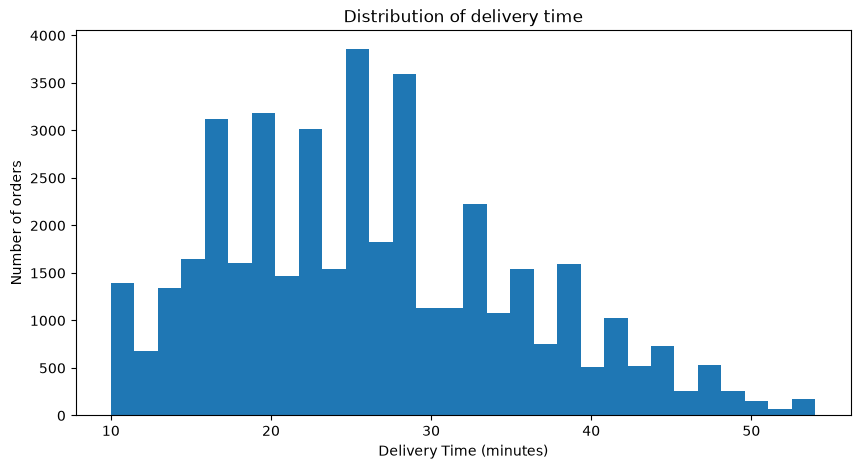

In [44]:
# Target Distribution

import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.hist(target_numeric.dropna(),bins = 30)
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of orders")
plt.title("Distribution of delivery time")
plt.show()


In [45]:
target_numeric.value_counts().sort_index()

Time_taken(min)
10     693
11     699
12     682
13     663
14     677
15    1645
16    1579
17    1546
18    1604
19    1675
20    1510
21    1465
22    1499
23    1512
24    1537
25    1899
26    1960
27    1826
28    1794
29    1795
30    1134
31    1128
32    1038
33    1186
34    1081
35     769
36     774
37     752
38     818
39     781
40     515
41     502
42     521
43     522
44     507
45     227
46     255
47     274
48     256
49     257
50      67
51      82
52      73
53      89
54      85
Name: count, dtype: Int64

In [46]:
# Checking realtionship between order time,pickup time, Target delivery Time

order_date = pd.to_datetime(
    df['Order_Date'],
    format='%d-%m-%Y',
    errors='coerce'
)
order_time = pd.to_timedelta(
    df['Time_Orderd'],
    errors='coerce'
)
pickup_time = pd.to_timedelta(
    df['Time_Order_picked'],
    errors='coerce'
)

order_Timestamp = order_date + order_time
pickup_timestamp = order_date + pickup_time

In [47]:
# calculating the raw difference
pickup_wait_time = (pickup_timestamp - order_Timestamp).dt.total_seconds() / 60
pickup_wait_time.describe()

count    40353.000000
mean       -16.037530
std        189.788237
min      -1439.500000
25%          5.516667
50%          9.283333
75%         13.133333
max         19.883333
dtype: float64

In [48]:
# negative pickup waits
negative_wait = pickup_wait_minutes < 0
print("Negative pickup waits : ",negative_wait.sum())
print("Percentage:",round(negative_wait.mean() * 100, 2))

Negative pickup waits :  794
Percentage: 1.89


In [49]:
df.loc[
    negative_wait,
    [
        "Order_Date",
        "Time_Orderd",
        "Time_Order_picked",
        'Time_taken(min)'
    ]
].head(20)

,Order_Date,Time_Orderd,Time_Order_picked,Time_taken(min)
32,11-02-2022,13:40:46,13:40:35,(min) 25
67,05-03-2022,23:55:26,0:09:32,(min) 10
91,26-03-2022,23:57:58,0:10:05,(min) 19
150,04-03-2022,23:49:49,0:02:33,(min) 19
360,12-02-2022,23:56:42,0:04:26,(min) 18
404,24-03-2022,23:46:00,0:03:47,(min) 15
495,17-03-2022,23:49:29,0:02:38,(min) 24
518,23-03-2022,23:55:47,0:05:22,(min) 11
525,20-03-2022,23:55:32,0:09:43,(min) 34
685,13-03-2022,23:47:32,0:00:12,(min) 10


In [50]:
pickup_wait_corrected = pickup_wait_minutes.copy()
pickup_wait_corrected.loc[negative_wait] += 24 * 60
pickup_wait_corrected.describe()

count    40353.000000
mean        12.296423
std         63.384520
min          0.000000
25%          5.783333
50%          9.500000
75%         13.266667
max       1439.983333
dtype: float64

In [57]:
extreme_pickup_wait = pickup_wait_corrected > 60

print("Pickup waits > 60 minutes:", extreme_pickup_wait.sum())
print(
    "Percentage:",
    round(extreme_pickup_wait.mean() * 100, 2)
)

Pickup waits > 60 minutes: 79
Percentage: 0.19


In [58]:
df.loc[
    extreme_pickup_wait,
    [
        "Order_Date",
        "Time_Orderd",
        "Time_Order_picked",
        "Time_taken(min)"
    ]
].head(30)

,Order_Date,Time_Orderd,Time_Order_picked,Time_taken(min)
32,11-02-2022,13:40:46,13:40:35,(min) 25
1713,21-03-2022,22:40:29,22:40:27,(min) 27
2455,23-03-2022,0:00:47,0:00:12,(min) 26
2918,17-02-2022,17:25:11,17:25:05,(min) 36
3312,07-03-2022,15:05:42,15:05:29,(min) 16
3761,11-03-2022,21:55:40,21:55:23,(min) 29
3803,01-03-2022,22:35:08,22:35:06,(min) 26
4975,02-03-2022,20:35:23,20:35:05,(min) 11
5399,10-03-2022,21:25:38,21:25:36,(min) 36
5817,13-02-2022,18:45:17,18:45:12,(min) 27


In [51]:
print(
    "Still negative:",
    (pickup_wait_corrected < 0).sum()
)

print(
    "Greater than 24 hours:",
    (pickup_wait_corrected > 24 * 60).sum()
)

Still negative: 0
Greater than 24 hours: 0


In [52]:
analysis_df = pd.DataFrame({
    "pickup_wait_minutes" : pickup_wait_corrected,
    "target_minutes" : target_numeric
})
analysis_df.describe()

,pickup_wait_minutes,target_minutes
count,40353.000000,41953.0
mean,12.296423,26.311539
std,63.384520,9.380753
min,0.000000,10.0
25%,5.783333,19.0
50%,9.500000,26.0
75%,13.266667,32.0
max,1439.983333,54.0


In [53]:
analysis_df.corr(numeric_only=True)

,pickup_wait_minutes,target_minutes
pickup_wait_minutes,1.000000,-0.000224
target_minutes,-0.000224,1.000000


In [54]:
analysis_df.head(20)

,pickup_wait_minutes,target_minutes
0,11.933333,24
1,6.200000,33
2,15.816667,26
3,8.900000,21
4,11.333333,30
5,6.866667,26
6,14.950000,40
7,2.616667,32
8,9.716667,34
9,11.450000,46


In [55]:
print("Target statistics")
print(target_numeric.describe())

print("\nPickup wait statistics")
print(pickup_wait_corrected.describe())

print("\nCorrelation")
print(
    analysis_df["pickup_wait_minutes"]
    .corr(analysis_df["target_minutes"])
)

Target statistics
count      41953.0
mean     26.311539
std       9.380753
min           10.0
25%           19.0
50%           26.0
75%           32.0
max           54.0
Name: Time_taken(min), dtype: Float64

Pickup wait statistics
count    40353.000000
mean        12.296423
std         63.384520
min          0.000000
25%          5.783333
50%          9.500000
75%         13.266667
max       1439.983333
dtype: float64

Correlation
-0.00022398713902619343


In [59]:
prediction_time_audit = pd.DataFrame([
    ["Delivery_person_Age", "Known at pickup", "Allowed"],
    ["Delivery_person_Ratings", "Known at pickup", "Allowed"],
    ["Restaurant_latitude", "Known at pickup", "Allowed"],
    ["Restaurant_longitude", "Known at pickup", "Allowed"],
    ["Delivery_location_latitude", "Known at pickup", "Allowed"],
    ["Delivery_location_longitude", "Known at pickup", "Allowed"],
    ["Order_Date", "Known at pickup", "Allowed"],
    ["Time_Orderd", "Known at pickup", "Potentially allowed"],
    ["Time_Order_picked", "Known at pickup", "Allowed"],
    ["Weatherconditions", "Weather condition associated with the delivery record", "Uncertain"],
    ["Road_traffic_density", "Known/estimated at pickup", "Allowed"],
    ["Vehicle_condition", "Known at pickup", "Allowed"],
    ["Type_of_order", "Known at pickup", "Allowed"],
    ["Type_of_vehicle", "Known at pickup", "Allowed"],
    ["multiple_deliveries", "Known at assignment/pickup", "Potentially allowed"],
    ["Festival", "Known at pickup", "Allowed"],
    ["City", "Known at pickup", "Allowed"],
    ["Delivery_person_ID", "Known at pickup", "Requires careful handling"],
])

prediction_time_audit.columns = [
    "feature",
    "availability",
    "decision"
]

prediction_time_audit

,feature,availability,decision
0,Delivery_person_Age,Known at pickup,Allowed
1,Delivery_person_Ratings,Known at pickup,Allowed
2,Restaurant_latitude,Known at pickup,Allowed
3,Restaurant_longitude,Known at pickup,Allowed
4,Delivery_location_latitude,Known at pickup,Allowed
5,Delivery_location_longitude,Known at pickup,Allowed
6,Order_Date,Known at pickup,Allowed
7,Time_Orderd,Known at pickup,Potentially allowed
8,Time_Order_picked,Known at pickup,Allowed
9,Weatherconditions,Weather condition associated with the delivery...,Uncertain


### Target Distribution Observation

The target variable ranges from 10 to 54 minutes and contains integer-valued
delivery durations.

The distribution is not uniform across the target range, with substantially
higher frequencies around the middle of the distribution and fewer observations
at the upper end.

No invalid or missing target values were identified during the raw-data audit.

No target outliers are removed at this stage because the observed range may
represent legitimate delivery-duration variation.

In [ ]:
extreme_pickup_wait = pickup_wait_corrected > 60
print('pickup wait > 60 minutes :',extreme_pickup_wait.sum())
print(
    "Percentage :",
    round(extreme_pickup_wait.mean() * 100,2)
)
df.loc[extreme_pickup_wait,
       [
           "Order_Date",
           "Time_Orderd",
           'Time_Order_picked',
           'Time_taken(min)'
       ]
].head(30)

pickup wait > 60 minutes : 79
Percentage : 0.19


,Order_Date,Time_Orderd,Time_Order_picked,Time_taken(min)
32,11-02-2022,13:40:46,13:40:35,(min) 25
1713,21-03-2022,22:40:29,22:40:27,(min) 27
2455,23-03-2022,0:00:47,0:00:12,(min) 26
2918,17-02-2022,17:25:11,17:25:05,(min) 36
3312,07-03-2022,15:05:42,15:05:29,(min) 16
3761,11-03-2022,21:55:40,21:55:23,(min) 29
3803,01-03-2022,22:35:08,22:35:06,(min) 26
4975,02-03-2022,20:35:23,20:35:05,(min) 11
5399,10-03-2022,21:25:38,21:25:36,(min) 36
5817,13-02-2022,18:45:17,18:45:12,(min) 27


## 7. Data Quality Findings

The raw dataset contains 41,953 records and 20 variables.

The audit identified the following characteristics:

- No duplicate complete records were identified.
- No duplicate order IDs were identified.
- Delivery-person IDs are repeated across multiple orders, which is expected.
- Several categorical and identifier fields contain leading or trailing whitespace.
- Missing values are represented both as actual nulls and string-like missing tokens.
- Several numerical variables are stored as strings in the raw dataset.
- The target variable `Time_taken(min)` is stored as a string with a `(min)` prefix.
- Order and pickup timestamps require parsing and temporal validation.
- Some order-to-pickup intervals appear negative because of midnight crossover or
  timestamp inconsistencies.
- A small number of unusually large order-to-pickup intervals require further
  validation during preprocessing.
- No target values were found outside the observed range of 10–54 minutes.

No records are removed during the data-understanding phase.
Data cleaning and transformation will be implemented reproducibly in the
next phase.

# 8. Phase 1 Conclusion

The raw dataset has been systematically inspected for schema consistency,
missing values, duplicates, categorical inconsistencies, numerical validity,
geographic validity, temporal structure, and target characteristics.

The dataset is suitable for further machine learning development, but requires
a reproducible preprocessing pipeline.

Key decisions for the next phase:

1. Preserve the original raw dataset unchanged.
2. Standardize missing-value representations.
3. Normalize whitespace in categorical/string fields.
4. Convert numerical fields to appropriate numeric types.
5. Parse date and time fields into proper temporal representations.
6. Investigate and handle anomalous order-to-pickup intervals.
7. Convert the target into a numeric representation.
8. Engineer geospatial and temporal features only after establishing
   prediction-time availability.
9. Exclude identifier fields from the initial baseline model unless a
   leakage-safe strategy justifies their use.
10. Perform explicit train/validation/test splitting before model training.